# 05 Geo tests and holdout sizing (findings 8 and 9)

**Methods demonstration: real data, simulated campaign.** Real Iowa county sales, with a campaign we add ourselves so the true answer is known. Write-ups: `docs/geo.md`, `docs/recommendation.md`.

In [1]:
from pathlib import Path
import json

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from incrementality.style import PAL, SOURCE, SOURCE_IOWA, apply, finish

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CRITEO = (ROOT / "data" / "processed" / "criteo_uplift.parquet").as_posix()
results = lambda name: json.loads((ROOT / "results" / f"{name}.json").read_text(encoding="utf-8"))
show = lambda name: display(Image(filename=str(ROOT / "figures" / name), width=900))
pd.set_option("display.float_format", "{:,.4f}".format)
apply()

In [2]:
from incrementality.geo import did, inject_lift, structural_ts, synthetic_control

panel = pd.read_parquet(ROOT / "data" / "processed" / "iowa_log_sales.parquet")
rng = np.random.default_rng(11)
test = list(rng.choice(panel.columns, 10, replace=False))
start, weeks, pre = len(panel) - 30, 8, 104
lifted = inject_lift(panel, test, start, weeks, 0.10)  # a +10% campaign we invented
pd.DataFrame([vars(m(lifted, test, start, weeks, pre)) for m in (did, synthetic_control, structural_ts)]).set_index("method")

,lift,lo,hi
method,,,
did,0.1223,0.0433,0.2073
synthetic_control,0.1582,0.0611,0.2642
structural_ts,0.1282,0.0494,0.2150


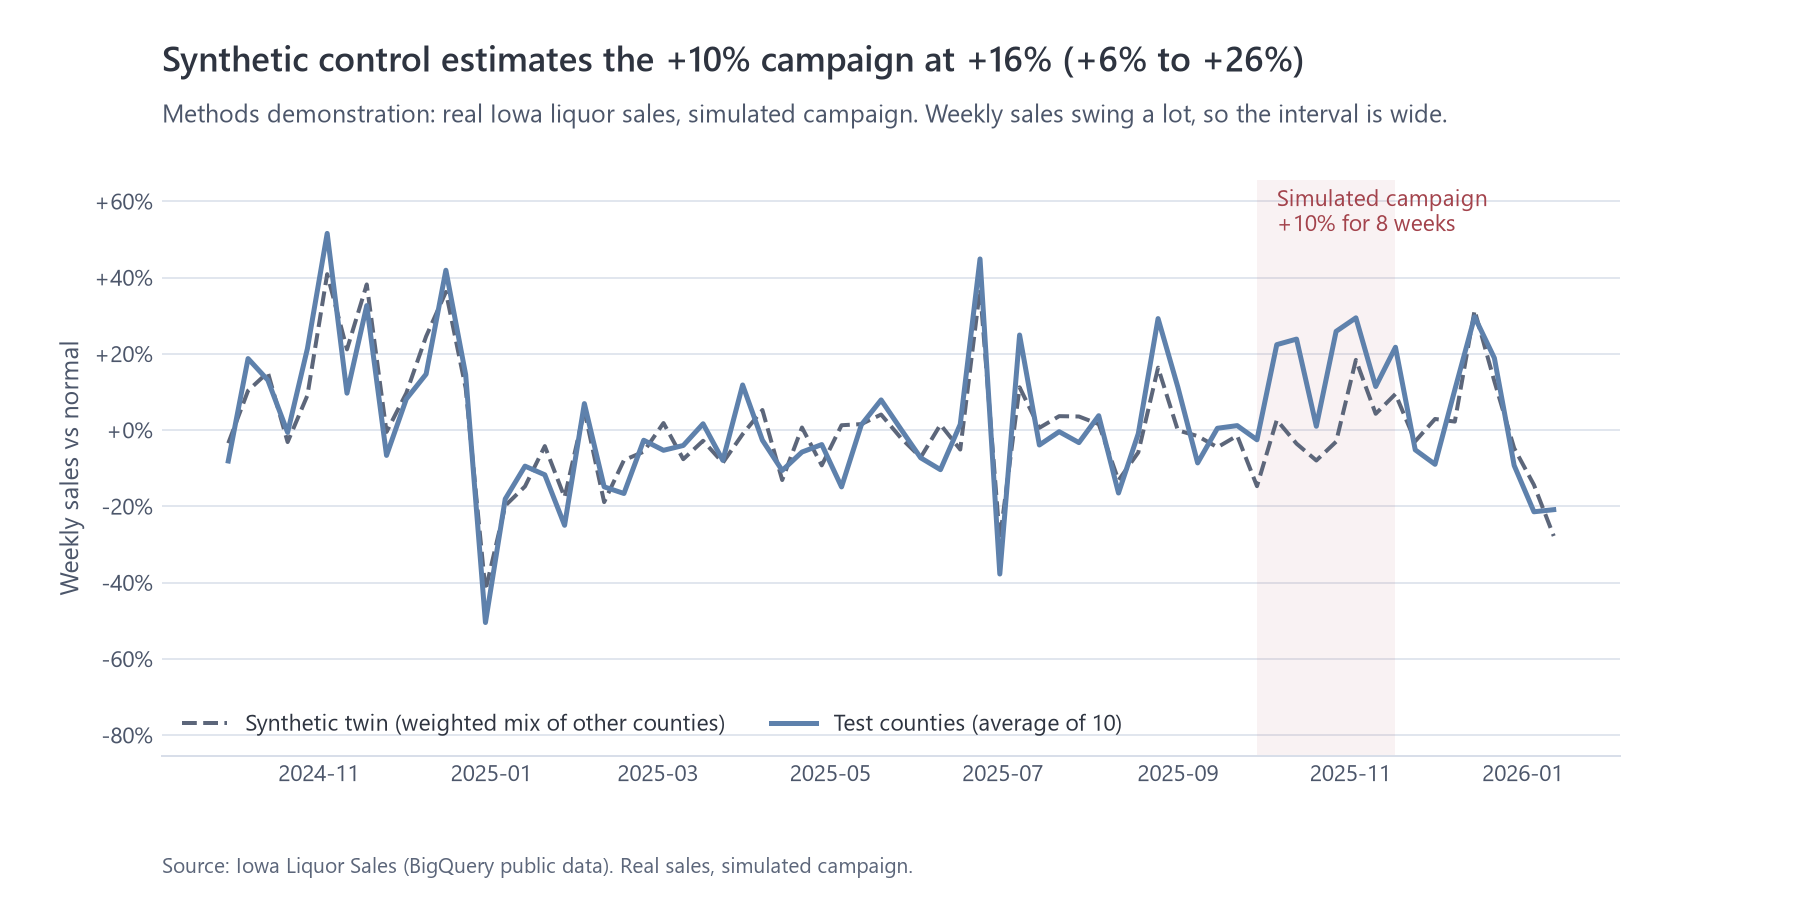

In [3]:
show("geo/example_test.png")

One test proves little. `geo_simulation.py` ran 2,700 tests with **no** campaign (9 designs x 300) and recorded how often each method cried wolf and how big a campaign it would have caught.

In [4]:
g = results("geo")
rows = [{"method": m, "design": k, "false alarms": v["false_alarm_rate"],
         "smallest lift detected (size-adjusted)": v["min_detectable_lift_size_adjusted"]}
        for m, cells in g["methods"].items() for k, v in cells.items()]
pd.DataFrame(rows).pivot(index="design", columns="method").style.format("{:.0%}")

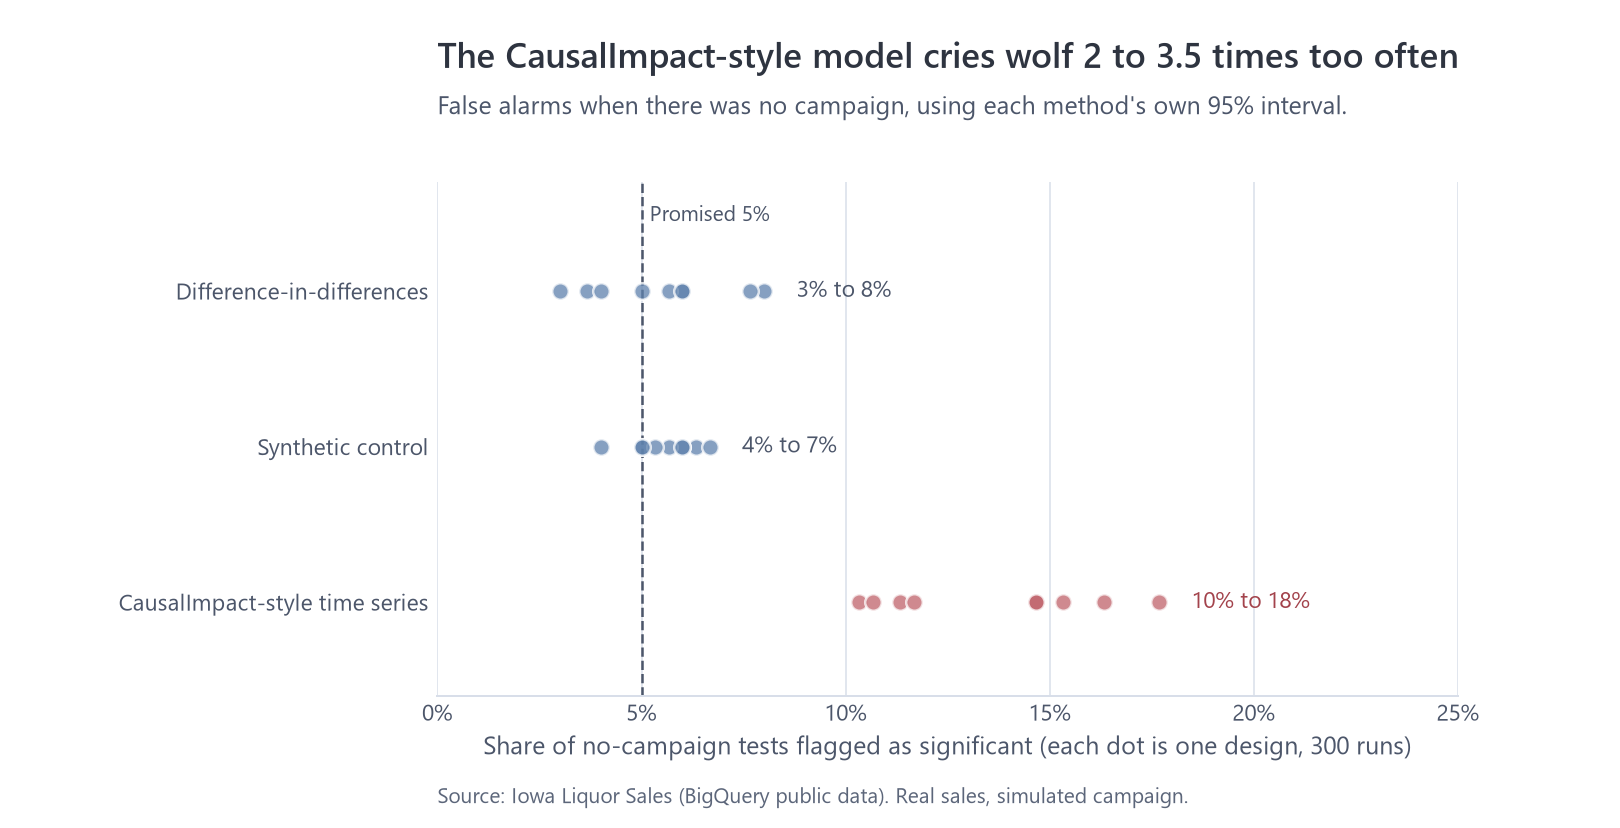

In [5]:
show("geo/false_alarms.png")

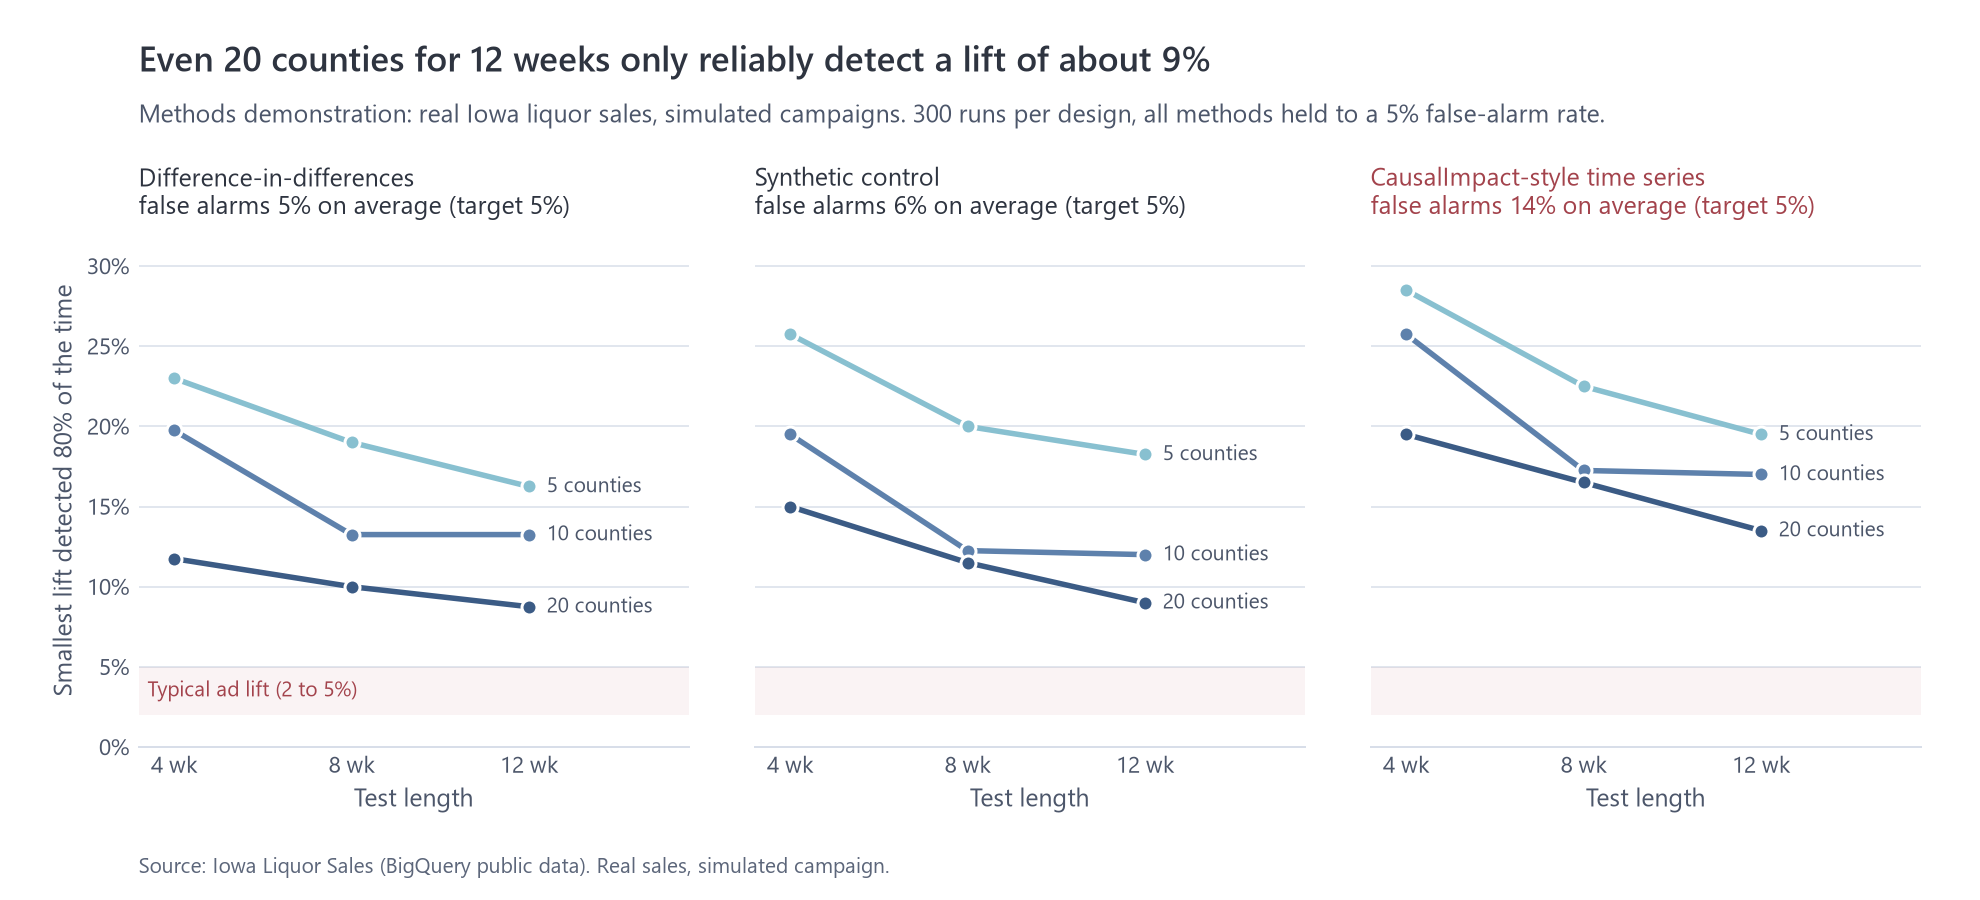

In [6]:
show("geo/min_detectable_lift.png")

## Finding 9: how big must a user-level holdout be?

In [7]:
from incrementality.planning import users_needed

p = results("plan")["outcomes"]
table = pd.DataFrame({f"{share:.0%} held out": [users_needed(lift, share, p["conversion"]["base_rate"]) / 1e6
                                                for lift in (0.2, 0.1, 0.05)] for share in (0.1, 0.15, 0.5)},
                     index=["+20% conversion lift", "+10%", "+5%"])
table.style.format("{:.1f}M users")

,10% held out,15% held out,50% held out
+20% conversion lift,1.4M users,1.0M users,0.5M users
+10%,4.9M users,3.5M users,1.8M users
+5%,18.9M users,13.3M users,6.8M users


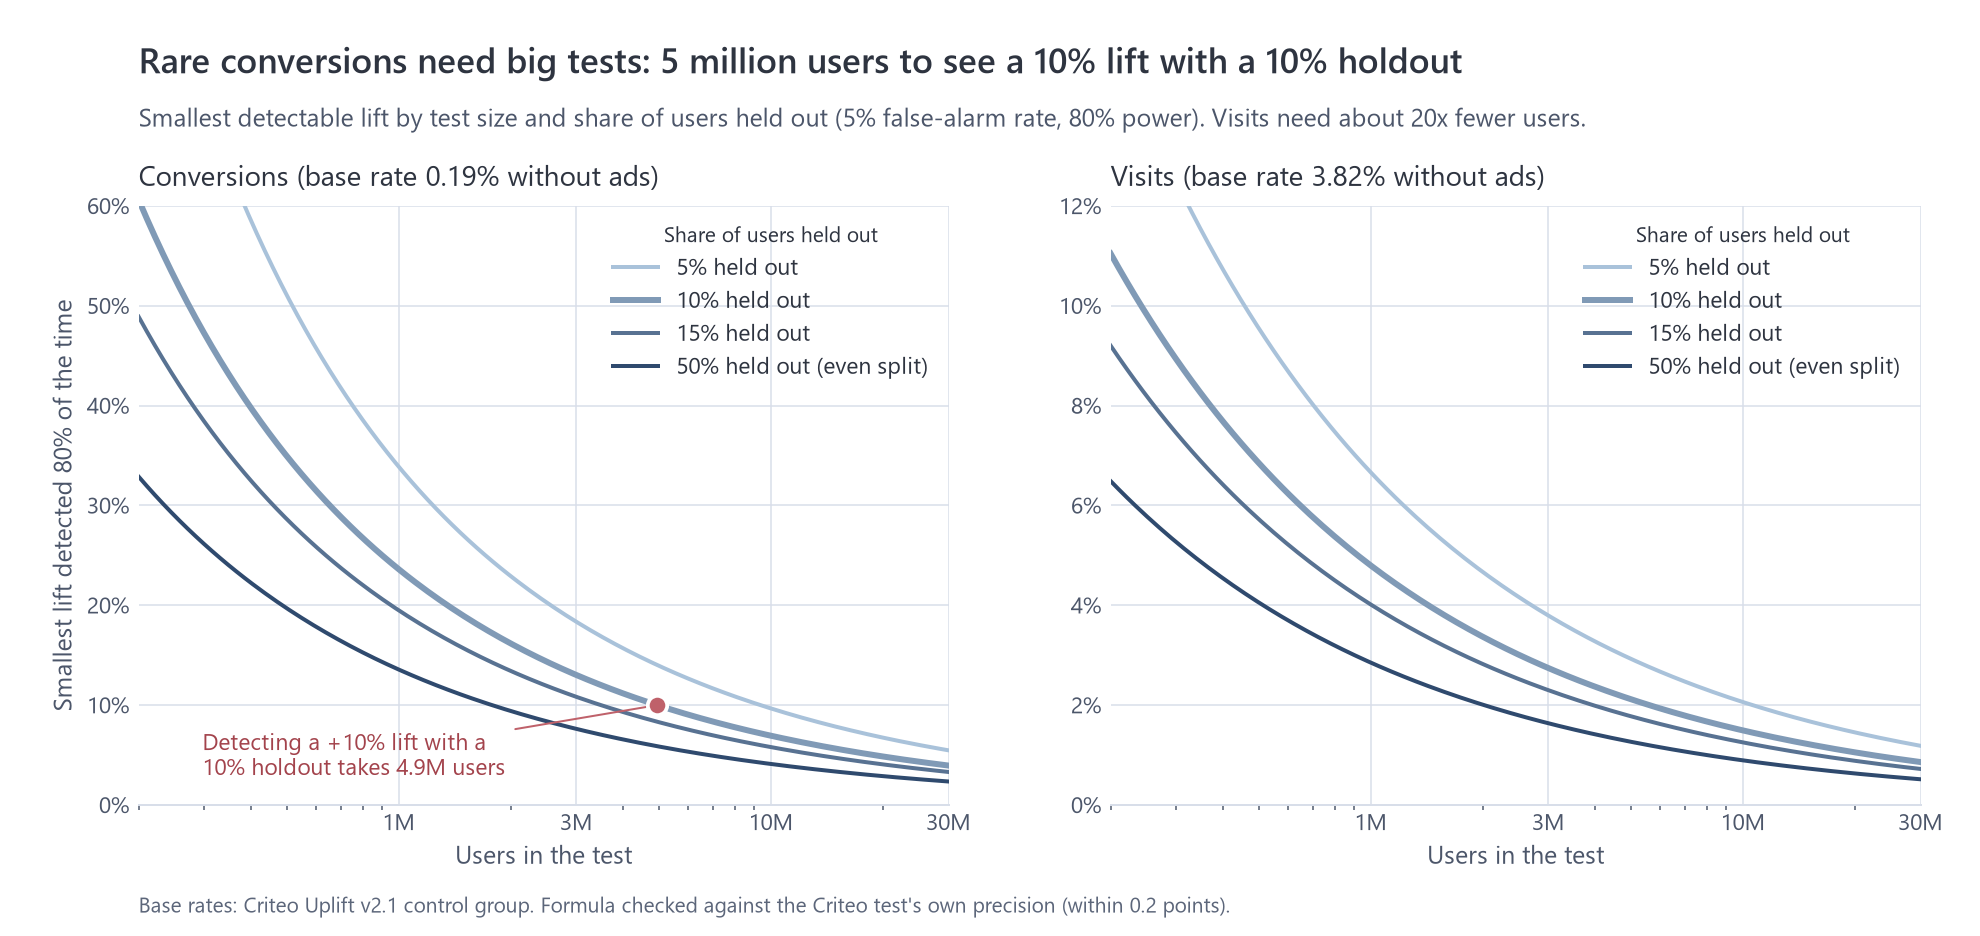

In [8]:
show("plan/holdout_sizing.png")